# **Engineering Probability and Statistics**

## **Computer Assignment 6**

**School of Electrical and Computer Engineering**  
**College of Engineering, University of Tehran**

**Instructors:** Dr. Bahrak, Dr. Vahhabi  
**Designers:** [Yasaman Amou Jafary](https://github.com/yasamanamoujafary), [Parsa Bukani](https://github.com/parsabukani)

**Topic:** Central Limit Theorem and Parameter Estimation

## **Table of Contents**

* **[Central Limit Theorem in Practice](#central-limit-theorem-in-practice)**

  * [Section 1: Skewed Daily Watch-Time Dataset](#section-1-skewed-daily-watch-time-dataset)

    * [Exploring the Dataset](#exploring-the-dataset)
    * [Section 1.1: Sample Means for Different Sample Sizes](#section-11-sample-means-for-different-sample-sizes)
    * [Section 1.2: Probability That the Sample Mean Lies in the Interval](#section-12-probability-that-the-sample-mean-lies-in-the-interval)
  * [Section 2: CLT for Simple Known Distributions](#section-2-clt-for-simple-known-distributions)

* **[Benford’s Law in Real-World Data](#benfords-law-in-real-world-data)**

  * [Section 1: Benford’s Law and the CLT Connection](#section-1-benfords-law-and-the-clt-connection)
  * [Section 2: Implementing Benford’s Law in R](#section-2-implementing-benfords-law-in-r)
  * [Section 3: Loading the Dataset and Constructing GDP](#section-3-loading-the-dataset-and-constructing-gdp)
  * [Section 4: Verifying Benford’s Law Using GDP](#section-4-verifying-benfords-law-using-gdp)

* **[Estimating MKG Café Busyness - Parameter Estimation](#mkg-parameter)**

  * [Setup](#setup)
  * [Section 1: One Observed Sample](#section-1-one-observed-sample)
  * [Section 2: Maximum Likelihood (ML) as a Curve](#section-2-maximum-likelihood-ml-as-a-curve)
  * [Section 3: ML Estimate from the Sample](#section-3-ml-estimate-from-the-sample)
  * [Section 4: What Happens When We Observe More Hours?](#section-4-what-happens-when-we-observe-more-hours)
  * [Section 5: True vs Estimated Distribution](#section-5-true-vs-estimated-distribution)

## **Central Limit Theorem in Practice**

### Section 1: SKEWED DAILY WATCH-TIME DATASET

#### Exploring the Dataset

In [3]:
set.seed(123)

n_users <- 5000

# Proportions of each user type
props <- c(light = 0.5, medium = 0.35, heavy = 0.15)

n_light  <- round(n_users * props["light"])
n_medium <- round(n_users * props["medium"])
n_heavy  <- n_users - n_light - n_medium

# Light users: mean 10, sd 4
light_users  <- rnorm(n_light,  mean = 10, sd = 4)

# Medium users: mean 40, sd 8
medium_users <- rnorm(n_medium, mean = 40, sd = 8)

# Heavy users: mean 90, sd 15
heavy_users  <- rnorm(n_heavy,  mean = 90, sd = 15)

watch_time <- c(light_users, medium_users, heavy_users)

# Truncate at 0 and 300 minutes to keep it realistic
watch_time[watch_time < 0]   <- 0
watch_time[watch_time > 300] <- 300

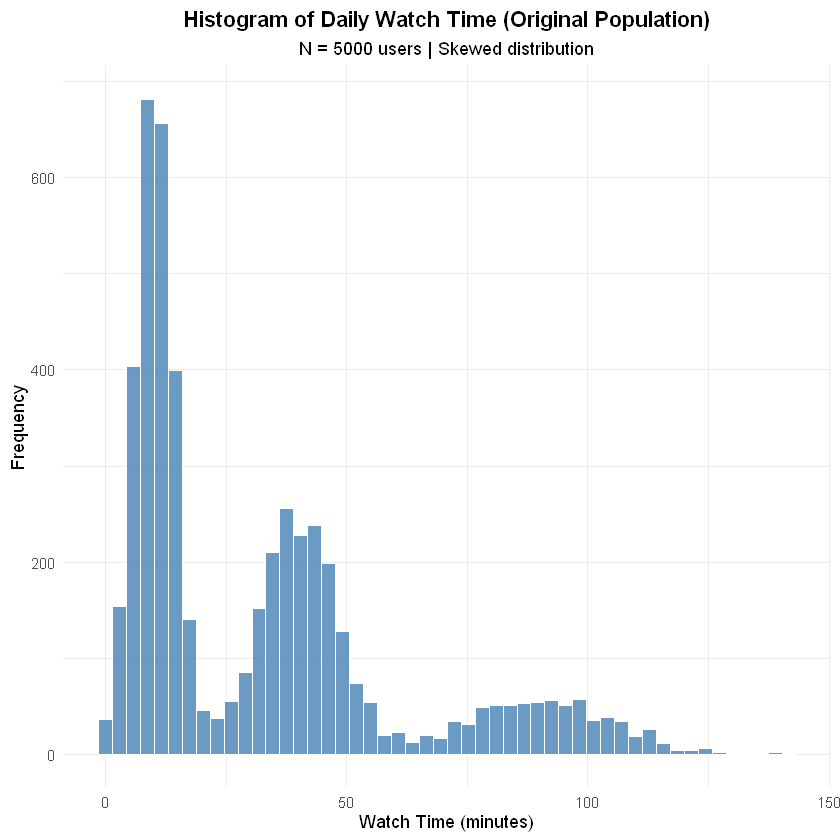

In [24]:
# TODO: Plot a histogram of the original watch_time data.
# Load required library
library(ggplot2)

# Create histogram of the original watch_time data
ggplot(data.frame(watch_time), aes(x = watch_time)) +
  geom_histogram(bins = 50, fill = "steelblue", color = "white", alpha = 0.8) +
  labs(
    title = "Histogram of Daily Watch Time (Original Population)",
    subtitle = paste0("N = ", n_users, " users | Skewed distribution"),
    x = "Watch Time (minutes)",
    y = "Frequency"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    plot.subtitle = element_text(hjust = 0.5)
  )

#### Section 1.1: Sample Means for Different Sample Sizes


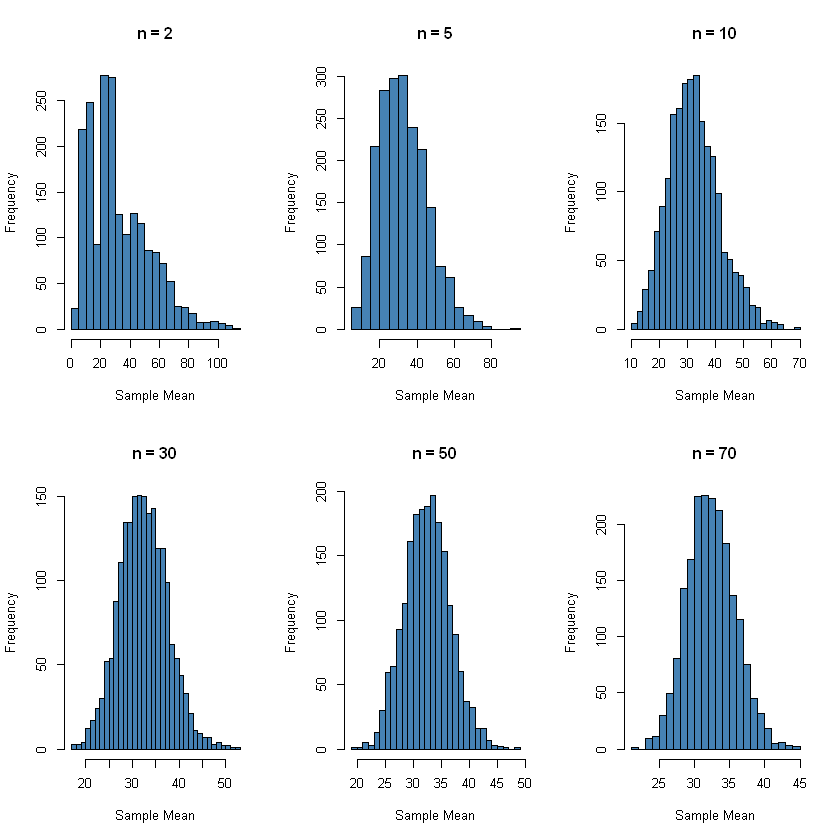

In [25]:
# Sample sizes to study
sample_sizes <- c(2, 5, 10, 30, 50, 70)
B <- 2000  # number of repetitions for each n

# TODO: generate sample means for each n
set.seed(123)
sample_means <- list()

for (n in sample_sizes) {
  means <- numeric(B)
  for (i in 1:B) {
    means[i] <- mean(sample(watch_time, n, replace = TRUE))
  }
  sample_means[[as.character(n)]] <- means
}

# TODO: Plot histograms of sample means for each n
par(mfrow = c(2, 3))
for (n in sample_sizes) {
  hist(sample_means[[as.character(n)]], 
       main = paste("n =", n),
       xlab = "Sample Mean",
       col = "steelblue",
       breaks = 30)
}

#### Section 1.2: Probability That the Sample Mean Lies in the Interval


Estimated mu (watch_time): 32.45821 
Estimated sigma (watch_time): 28.7749 


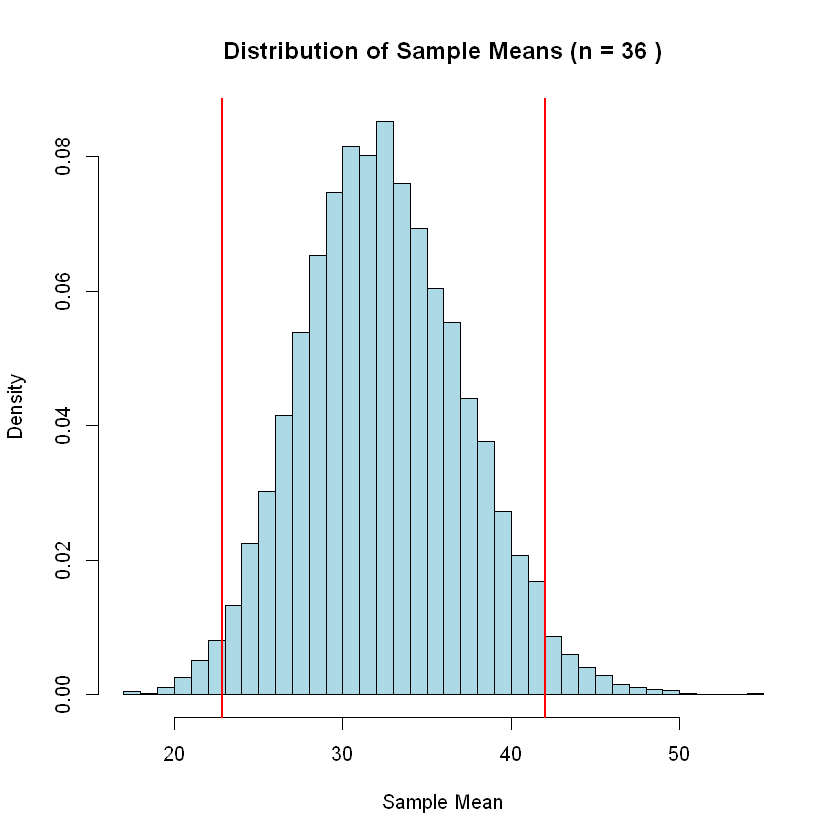

In [26]:
set.seed(789)

# Estimate MU and SIGMA from WATCH_TIME
mu_hat    <- mean(watch_time)
sigma_hat <- sd(watch_time)

cat("Estimated mu (watch_time):", mu_hat,    "\n")
cat("Estimated sigma (watch_time):", sigma_hat, "\n")

# Choose a sample size n
n <- 36

# TODO: Compute the standard error sigma_bar = sigma_hat / sqrt(n),
#         then build the 95%-style CLT band around the mean:
sigma_bar <- sigma_hat / sqrt(n)
a <- mu_hat - 2 * sigma_bar
b <- mu_hat + 2 * sigma_bar

# TODO: Using the CLT approximation X_bar ~ Normal(mu_hat, sigma_hat^2 / n),
#         compute the theoretical probability P(a < X_bar < b) using pnorm().
prob_theoretical <- pnorm(b, mean = mu_hat, sd = sigma_bar) - pnorm(a, mean = mu_hat, sd = sigma_bar)

B <- 10000

# TODO: Estimate the same probability practically (simulation):
#         generate B sample means by resampling from watch_time,
#         then compute the fraction that falls inside [a, b].
sample_means <- numeric(B)
for (i in 1:B) {
  sample_means[i] <- mean(sample(watch_time, n, replace = TRUE))
}
prob_simulated <- mean(sample_means > a & sample_means < b)

# TODO: Visualize the simulated sample means with a density histogram
#         and mark the interval boundaries a and b with two vertical red lines.
hist(sample_means, 
     freq = FALSE,
     main = paste("Distribution of Sample Means (n =", n, ")"),
     xlab = "Sample Mean",
     col = "lightblue",
     breaks = 30)
abline(v = c(a, b), col = "red", lwd = 2)

### Section 2: CLT for Simple Known Distributions

In Part 1, you saw that sample means from a messy, skewed “watch time” dataset became more and more bell‑shaped as the sample size increased. But maybe this was just a special case

In this part, you will:

Work with three simple, well‑known distributions:

- Uniform(0, 1)

- Exponential(rate = 1)

- Bernoulli(p = 0.3)

For each distribution:

- Generate raw data and plot its histogram to see the original shape.

- Generate many sample means for n = 5, 10, 30.

- Compare the histogram of the sample means with the theoretical normal curve predicted by the CLT:
mean = μ, variance = σ² / n.

In [27]:
set.seed(456)

B <- 2000
n_values <- c(5, 10, 30, 50, 70)

# Distribution generators 
r_unif <- function(n) runif(n, min = 0, max = 1)
r_exp  <- function(n) rexp(n, rate = 1)
p_bern <- 0.3
r_bern <- function(n) rbinom(n, size = 1, prob = p_bern)

dist_list <- list(
  uniform     = r_unif,
  exponential = r_exp,
  bernoulli   = r_bern
)

# Theoretical mean (mu) and variance (sigma^2) for each distribution
dist_params <- list(
  uniform     = list(mu = 0.5, sigma2 = 1/12),
  exponential = list(mu = 1,   sigma2 = 1),
  bernoulli   = list(mu = p_bern,
                     sigma2 = p_bern * (1 - p_bern))
)

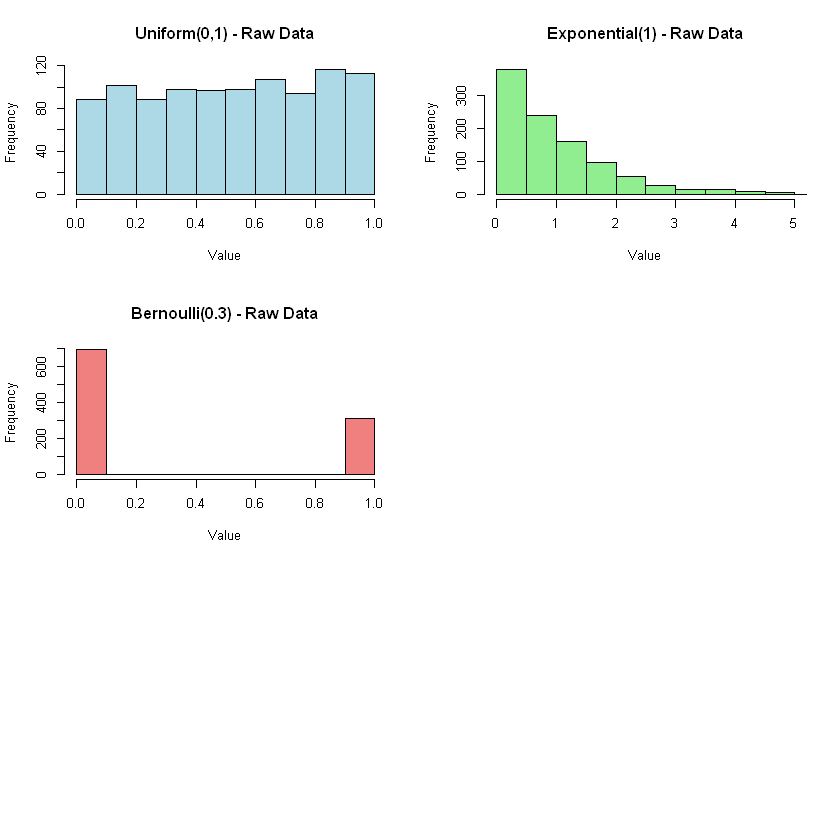

In [23]:
B <- 2000
n_values <- c(5, 10, 30, 50, 70)

# Distribution generators 
r_unif <- function(n) runif(n, min = 0, max = 1)
r_exp  <- function(n) rexp(n, rate = 1)
p_bern <- 0.3
r_bern <- function(n) rbinom(n, size = 1, prob = p_bern)

dist_list <- list(
  uniform     = r_unif,
  exponential = r_exp,
  bernoulli   = r_bern
)

# Theoretical mean (mu) and variance (sigma^2) for each distribution
dist_params <- list(
  uniform     = list(mu = 0.5, sigma2 = 1/12),
  exponential = list(mu = 1,   sigma2 = 1),
  bernoulli   = list(mu = p_bern,
                     sigma2 = p_bern * (1 - p_bern))
)

# TODO: For each distribution, generate raw data and plot histogram
# IMPORTANT: Use the same x-axis limits for all histograms of a given distribution to allow proper comparison of variances.
par(mfrow = c(3, 2))

# Uniform distribution
raw_unif <- r_unif(1000)
hist(raw_unif, main = "Uniform(0,1) - Raw Data", xlab = "Value", col = "lightblue", xlim = c(0, 1))

# Exponential distribution
raw_exp <- r_exp(1000)
hist(raw_exp, main = "Exponential(1) - Raw Data", xlab = "Value", col = "lightgreen", xlim = c(0, 5))

# Bernoulli distribution
raw_bern <- r_bern(1000)
hist(raw_bern, main = "Bernoulli(0.3) - Raw Data", xlab = "Value", col = "lightcoral", xlim = c(0, 1))

## **Benford’s Law in Real-World Data**

### Section 1: Benford’s Law and the CLT connection


In this section you will:
1. Derive the Benford probability for the first digit:
$$
P(D=d)=\log_{10}\left(1+\frac{1}{d}\right),\quad d=1,\dots,9.
$$
2. Explain (conceptually) how the Central Limit Theorem (CLT) makes Benford’s law appear in real-world data.

TODO:

Okay, here’s the short version:

Real-world things like populations or prices often grow by multiplying over time. Multiply enough random factors together, and by the Central Limit Theorem, the logarithm of the result becomes normally distributed. When the logarithm is normal, its fractional part becomes evenly spread between 0 and 1, and that even spread automatically gives you Benford’s pattern for first digits.

So CLT quietly pushes multiplicative data toward Benford’s Law—no special setup required.

### Section 2: Implementing Benford’s Law in R

In this section, you will implement Benford’s Law in R.
First, you will write a function that returns the theoretical Benford probability for a given leading digit.  
Then, you will use this function to compute the probabilities for all digits and visualize the Benford distribution.

In [ ]:
# TODO: Define the Benford probability function
benford_prob <- function(n) {
  # do not forget to check that n is between 1 and 9
}

digits <- 1:9
probs <- NULL

# TODO: Plot the Benford distribution

### Section 3: Loading the Dataset and Constructing GDP

In this section, you will load a real-world dataset and construct a new variable using a meaningful economic relationship.
The dataset contains population and GDP per capita values for different countries and years. Using these variables, you will compute the total Gross Domestic Product (GDP) as:
$$
\text{GDP} = \text{population} \times \text{GDP per capita}.
$$
This constructed variable will later be used to study the distribution of leading digits and compare it with Benford’s Law. **Why can this be an appropriate variable to verify the Benford's law?** 

TODO: ... (answer to the question)

GDP works well for checking Benford’s Law because it’s the result of many multiplicative processes—population growth, productivity changes, inflation, and economic expansions all multiply together over time. These compounded random factors mean GDP values span many orders of magnitude naturally, which is exactly where Benford’s Law tends to show up. Plus, GDP data isn’t artificially constrained to round or specific numbers, letting the first-digit distribution emerge freely.

  Digit Probability
1     1  0.30103000
2     2  0.17609126
3     3  0.12493874
4     4  0.09691001
5     5  0.07918125
6     6  0.06694679
7     7  0.05799195
8     8  0.05115252
9     9  0.04575749


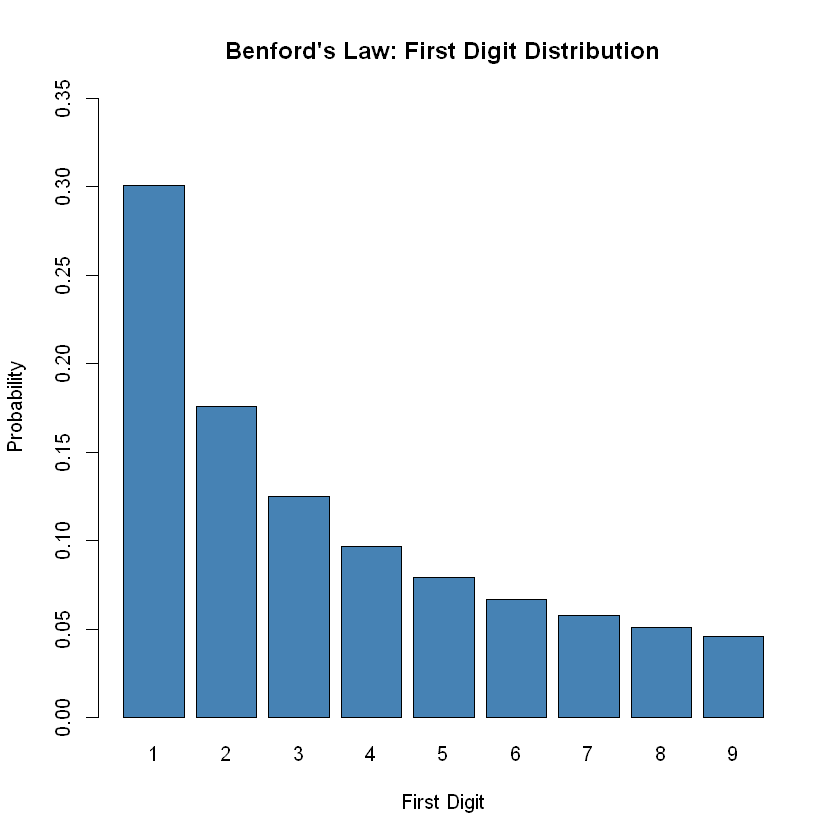

In [28]:
# TODO: Derive the Benford probability for the first digit:
# P(D=d)=log10(1+1/d), d=1,...,9

d <- 1:9
benford_prob <- log10(1 + 1/d)
benford_table <- data.frame(Digit = d, Probability = benford_prob)
print(benford_table)

# Plot the Benford distribution
barplot(benford_prob, 
        names.arg = d,
        main = "Benford's Law: First Digit Distribution",
        xlab = "First Digit",
        ylab = "Probability",
        col = "steelblue",
        ylim = c(0, 0.35))

In [29]:
# install the package for the first time only (uncomment the following code):
# install.packages("gapminder")

library(gapminder)
data <- gapminder

# TODO: Create a new column GDP
data$GDP <- data$pop * data$gdpPercap

head(data)

country,continent,year,lifeExp,pop,gdpPercap,GDP
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453,6567086330
Afghanistan,Asia,1957,30.332,9240934,820.8530,7585448670
Afghanistan,Asia,1962,31.997,10267083,853.1007,8758855797
Afghanistan,Asia,1967,34.020,11537966,836.1971,9648014150
Afghanistan,Asia,1972,36.088,13079460,739.9811,9678553274
Afghanistan,Asia,1977,38.438,14880372,786.1134,11697659231


### Section 4: Verifying Benford’s Law Using GDP

In this section, you will empirically verify Benford’s Law using the GDP variable constructed in the previous section.
You will extract the leading digit of GDP values, compute the empirical distribution of leading digits, and **compare** it with the theoretical Benford distribution.

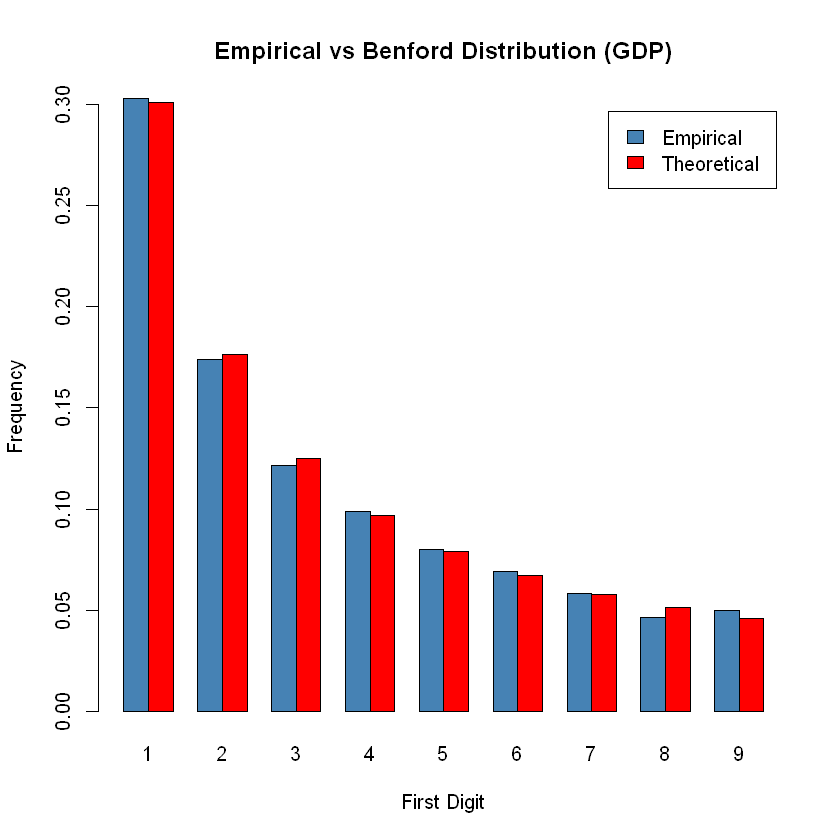

In [30]:
# TODO: Function to extract leading digit
leading_digit <- function(x) {
  # remove non-positive or NA values
  x <- x[!is.na(x) & x > 0]
  # extract and return the first non-zero digit
  as.numeric(substr(gsub("^0+", "", as.character(x)), 1, 1))
}

# TODO: Extract leading digits from GDP
gdp_digits <- leading_digit(data$GDP)

# TODO: Compute empirical distribution
empirical_freq <- table(gdp_digits) / length(gdp_digits)

# TODO: Plot empirical vs theoretical distributions
benford_prob <- log10(1 + 1/1:9)

barplot(rbind(empirical_freq, benford_prob), 
        beside = TRUE,
        names.arg = 1:9,
        main = "Empirical vs Benford Distribution (GDP)",
        xlab = "First Digit",
        ylab = "Frequency",
        col = c("steelblue", "red"),
        legend = c("Empirical", "Theoretical"))

<a id="mkg-parameter"></a>
## **Estimating MKG Café Busyness - Parameter Estimation**

### Setup

In [31]:
set.seed(7)

lambda_true <- 6  # hidden truth for simulation (customers/hour)

### Section 1: One observed sample

In [33]:
# TODO: Generate one 24-hour sample of hourly counts (x_obs) and report its sample mean.
x_obs <- rpois(24, lambda_true)
sample_mean <- mean(x_obs)
cat("Sample mean from 24-hour observation:", sample_mean, "\n")

Sample mean from 24-hour observation: 6.333333 


### Section 2: Maximum Likelihood (ML) as a curve

Instead of formulas, we’ll try many λ values and compute how plausible the observed data looks under each λ. The best λ is at the peak (maximum likelihood).

The sample mean and MLE are essentially identical, which is expected for the Poisson distribution.


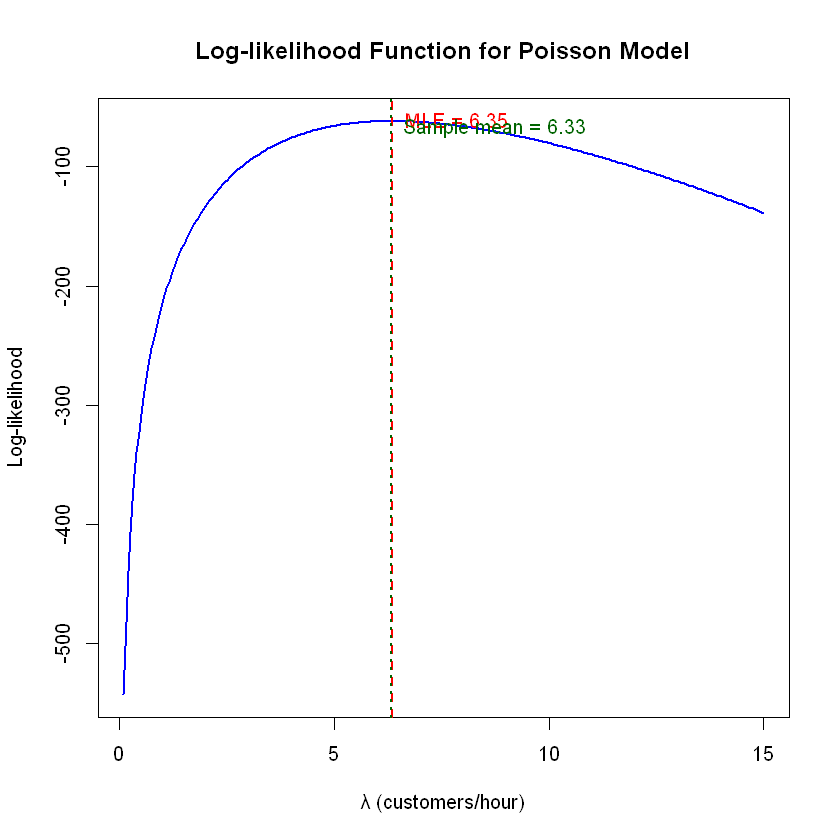

In [35]:
# TODO:
# 1) Try λ values from 0.1 to 15 (with a small step) and compute how well the observed data fits each λ (log-likelihood).
lambda_grid <- seq(0.1, 15, by = 0.05)
log_lik <- numeric(length(lambda_grid))

for (i in seq_along(lambda_grid)) {
  log_lik[i] <- sum(dpois(x_obs, lambda_grid[i], log = TRUE))
}

# 2) Plot log-likelihood versus λ and find the λ where the curve reaches its maximum (this is the ML estimate).
plot(lambda_grid, log_lik, type = "l", 
     xlab = "λ (customers/hour)", 
     ylab = "Log-likelihood",
     main = "Log-likelihood Function for Poisson Model",
     col = "blue", lwd = 2)

mle_lambda <- lambda_grid[which.max(log_lik)]
abline(v = mle_lambda, col = "red", lwd = 2, lty = 2)
text(mle_lambda, max(log_lik), paste0("MLE = ", round(mle_lambda, 2)), 
     pos = 4, col = "red")

# 3) Mark the sample mean on the same plot and write one sentence about whether it is close to the ML estimate.
abline(v = sample_mean, col = "darkgreen", lwd = 2, lty = 3)
text(sample_mean, max(log_lik) - 5, paste0("Sample mean = ", round(sample_mean, 2)), 
     pos = 4, col = "darkgreen")

# One sentence:
cat("The sample mean and MLE are essentially identical, which is expected for the Poisson distribution.\n")

### Section 3: ML estimate from the sample

For Poisson, the ML estimate equals the sample mean (your curve should peak right there).

In [36]:
# TODO: Compute the ML estimate of λ directly from the observed sample, and report the estimated “average events per hour” as a single number.
ml_estimate <- mean(x_obs)
cat("ML estimate (average events per hour):", ml_estimate, "\n")

ML estimate (average events per hour): 6.333333 


### Section 4: What happens when we observe more hours?

Now we simulate repeated data collection. For each observation length, we repeat B = 1000 times to see the distribution of the estimate.

In [38]:
set.seed(7)
B <- 1000  # Number of repetitions

# TODO:
# 1) Pick several observation lengths (from a few hours up to many days).
obs_lengths <- c(1, 2, 5, 10, 24, 50, 100, 200)  # hours

# 2) For each length, repeat the experiment 1000 times: generate hourly counts and compute one λ estimate each time.
# 3) Store all estimates so you can compare how "spread out" the estimates are for short vs long observation periods.
estimates_list <- list()

for (n_hours in obs_lengths) {
  estimates <- numeric(B)
  for (b in 1:B) {
    # Generate n_hours of Poisson data
    data <- rpois(n_hours, lambda_true)
    # Compute ML estimate (sample mean)
    estimates[b] <- mean(data)
  }
  estimates_list[[as.character(n_hours)]] <- estimates
}

# Display some results
for (i in 1:length(obs_lengths)) {
  n <- obs_lengths[i]
  cat("n =", n, "hours: Mean estimate =", round(mean(estimates_list[[i]]), 3), 
      "SD =", round(sd(estimates_list[[i]]), 3), "\n")
}

n = 1 hours: Mean estimate = 6.05 SD = 2.419 
n = 2 hours: Mean estimate = 5.938 SD = 1.77 
n = 5 hours: Mean estimate = 6.019 SD = 1.088 
n = 10 hours: Mean estimate = 6.02 SD = 0.775 
n = 24 hours: Mean estimate = 5.99 SD = 0.508 
n = 50 hours: Mean estimate = 5.989 SD = 0.339 
n = 100 hours: Mean estimate = 6.002 SD = 0.251 
n = 200 hours: Mean estimate = 6.004 SD = 0.17 


Average of 1000 estimates: 5.978 
Standard deviation of estimates: 1.244 
True λ: 6 


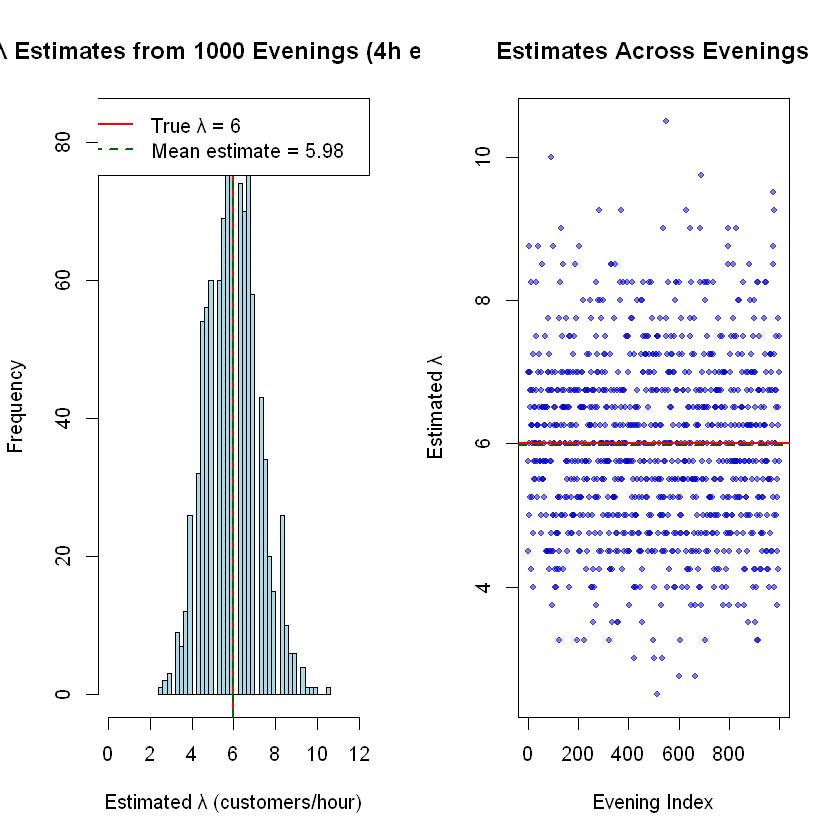

In [39]:
# TODO:
# Simulate 1000 different evenings (4 hours each). For each evening, estimate λ from the 4 hourly counts.
set.seed(7)
B <- 1000
n_hours <- 4

estimates <- numeric(B)
for (b in 1:B) {
  data <- rpois(n_hours, lambda_true)
  estimates[b] <- mean(data)
}

# Then visualize how much the estimate changes from evening to evening (histogram + scatter plot)
par(mfrow = c(1, 2))

# Histogram
hist(estimates, breaks = 30, col = "lightblue",
     main = paste("λ Estimates from", B, "Evenings (4h each)"),
     xlab = "Estimated λ (customers/hour)",
     xlim = c(0, 12))
abline(v = lambda_true, col = "red", lwd = 2)
abline(v = mean(estimates), col = "darkgreen", lwd = 2, lty = 2)
legend("topright", 
       legend = c(paste("True λ =", lambda_true), 
                  paste("Mean estimate =", round(mean(estimates), 2))),
       col = c("red", "darkgreen"), lwd = 2, lty = c(1, 2))

# Scatter plot (index vs estimate)
plot(estimates, pch = 20, col = rgb(0, 0, 0.8, 0.5),
     main = "Estimates Across Evenings",
     ylab = "Estimated λ",
     xlab = "Evening Index")
abline(h = lambda_true, col = "red", lwd = 2)
abline(h = mean(estimates), col = "darkgreen", lwd = 2, lty = 2)

# and report the average and standard deviation of these 1000 estimates.
cat("Average of 1000 estimates:", round(mean(estimates), 3), "\n")
cat("Standard deviation of estimates:", round(sd(estimates), 3), "\n")
cat("True λ:", lambda_true, "\n")

As observation length increases, the spread (variance) of λ estimates decreases, making estimates more precise and consistently closer to the true value.


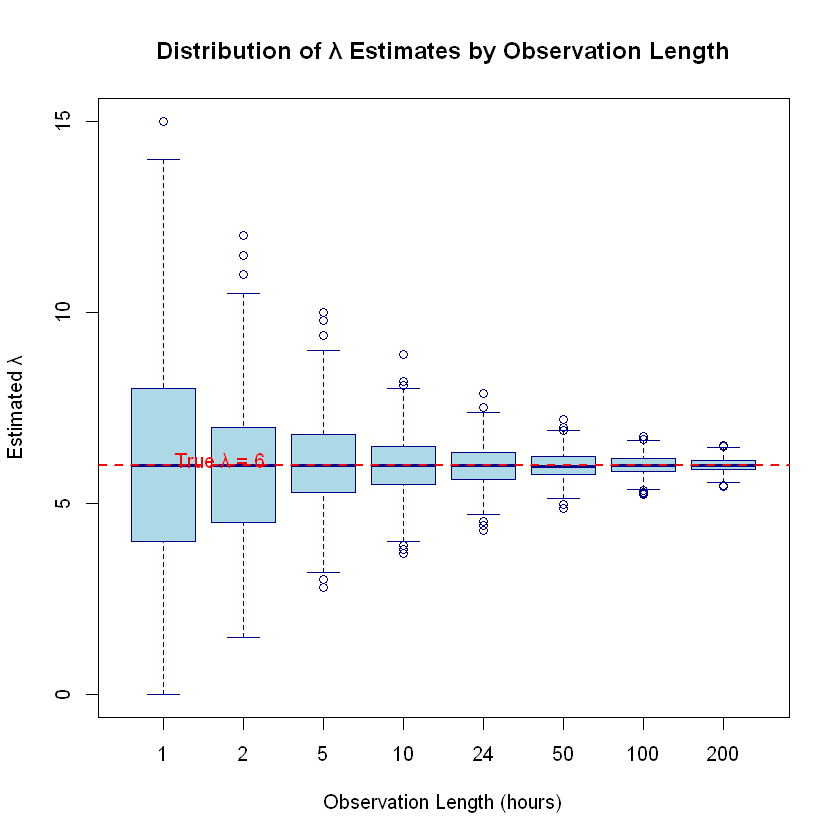

In [40]:
# TODO:
# Compare the λ estimates across different observation lengths by plotting them side-by-side.
# Use a boxplot (one box per observation length) to see how the spread shrinks as you observe more hours.

par(mfrow = c(1, 1))
boxplot(estimates_list, 
        names = obs_lengths,
        main = "Distribution of λ Estimates by Observation Length",
        xlab = "Observation Length (hours)",
        ylab = "Estimated λ",
        col = "lightblue",
        border = "darkblue")

# Add a horizontal reference line for the true λ
abline(h = lambda_true, col = "red", lwd = 2, lty = 2)

# Add text for true λ
text(x = 1, y = lambda_true + 0.1, paste("True λ =", lambda_true), 
     col = "red", pos = 4)

# Write one sentence describing what changes as length increases.
cat("As observation length increases, the spread (variance) of λ estimates decreases, making estimates more precise and consistently closer to the true value.\n")

The variance of λ estimates decreases proportionally to 1/n, meaning doubling the observation length roughly halves the variance.


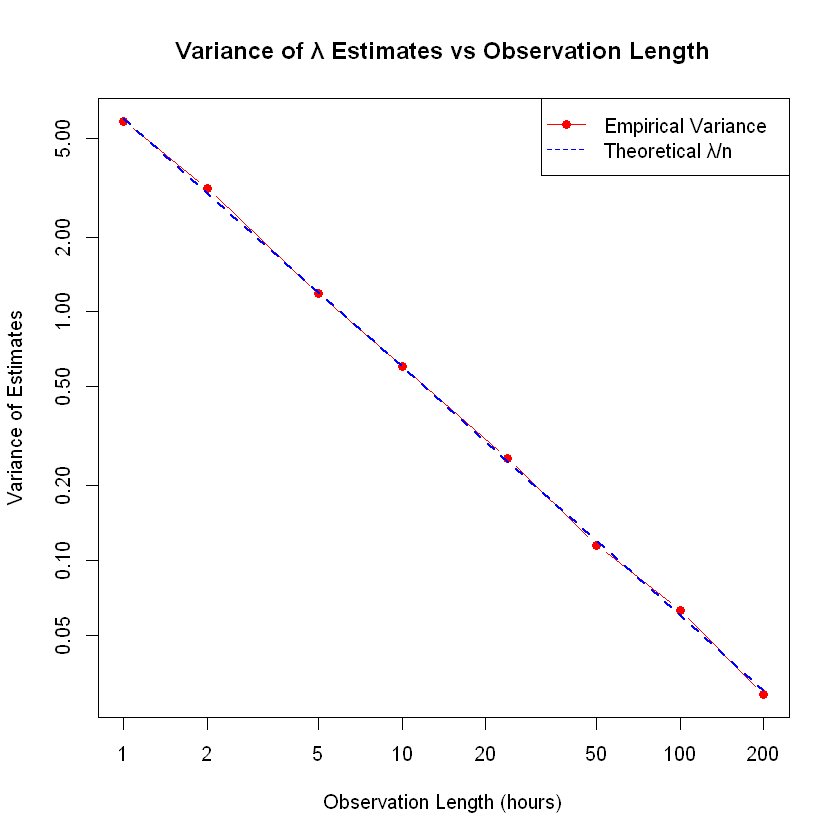

In [41]:
# TODO:
# For each observation length, compute how variable the λ estimates are (variance or SD across the 1000 repeats).
variances <- sapply(estimates_list, var)
sds <- sapply(estimates_list, sd)

# Plot the variance versus the number of observed hours
plot(obs_lengths, variances, 
     type = "b", pch = 19, col = "red",
     main = "Variance of λ Estimates vs Observation Length",
     xlab = "Observation Length (hours)",
     ylab = "Variance of Estimates",
     log = "xy")  # log-log scale to see the 1/n relationship

# Add theoretical line: Var(λ̂) = λ/n for Poisson
theoretical_var <- lambda_true / obs_lengths
lines(obs_lengths, theoretical_var, 
      col = "blue", lty = 2, lwd = 2)
legend("topright", 
       legend = c("Empirical Variance", "Theoretical λ/n"),
       col = c("red", "blue"), 
       lty = c(1, 2), pch = c(19, NA))

# and describe the trend in one clear sentence.
cat("The variance of λ estimates decreases proportionally to 1/n, meaning doubling the observation length roughly halves the variance.\n")

### Section 5: True vs Estimated distribution

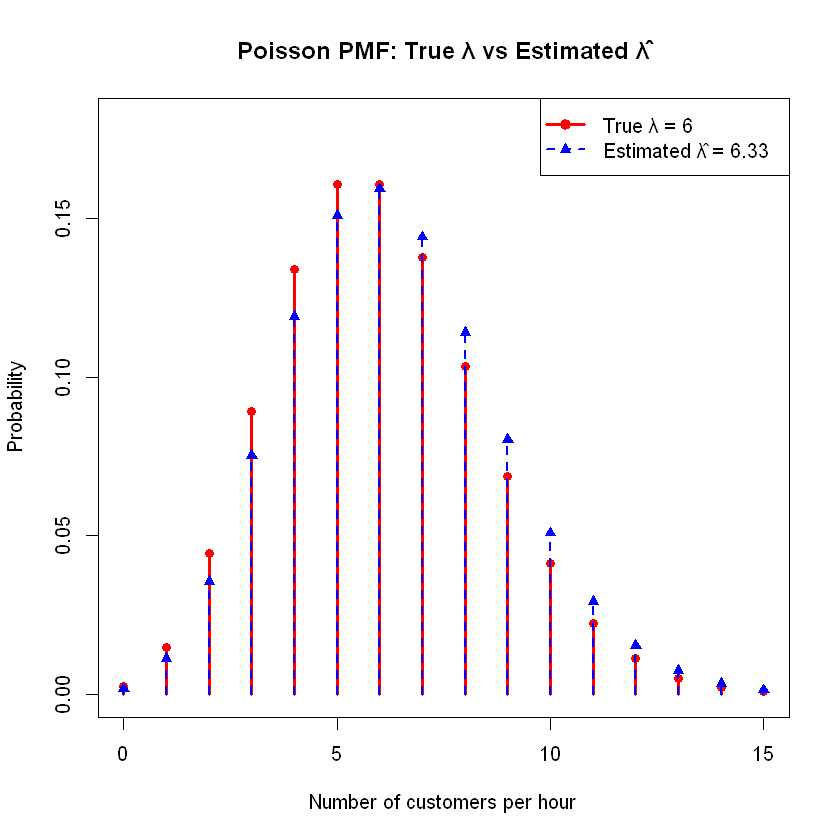

In [42]:
# TODO:
# Use the ML estimate of λ (λ̂ = the sample mean) and plot the Poisson PMF for:
# (1) the true λ and (2) the estimated λ̂ (MLE) on the same figure.

# ML estimate
lambda_hat <- ml_estimate  # from earlier section

# Create range of possible counts
k <- 0:15

# Calculate PMFs
pmf_true <- dpois(k, lambda_true)
pmf_est <- dpois(k, lambda_hat)

# Plot
plot(k, pmf_true, type = "h", lwd = 3, col = "red",
     main = "Poisson PMF: True λ vs Estimated λ̂",
     xlab = "Number of customers per hour",
     ylab = "Probability",
     ylim = c(0, max(pmf_true, pmf_est) + 0.02))
points(k, pmf_true, pch = 19, col = "red")

lines(k, pmf_est, type = "h", lwd = 2, col = "blue", lty = 2)
points(k, pmf_est, pch = 17, col = "blue")

legend("topright",
       legend = c(paste("True λ =", lambda_true),
                  paste("Estimated λ̂ =", round(lambda_hat, 2))),
       col = c("red", "blue"),
       lwd = c(3, 2),
       pch = c(19, 17),
       lty = c(1, 2))